# Saved evidence for a finite full-XX reusable-bath prototype

The one-spin component run completed 165 selected tests, two source exports,
17 compact circuit checks and 81 distinct ODE solves. Its overall validation
stopped during the original notebook-display stage. A later corrected
saved-only replay completed all five code cells locally without errors.
These are separate results: component evidence and a read-and-display replay.

This notebook authenticates and displays the same saved data. Its code cells
do not repeat quantum evolution, ODE solves, tests, source generation,
sampling, synthesis or resource estimation. The code cells match the locally
replayed version; the explanatory Markdown has been clarified afterwards.
The original executed receipt and failed-run history are preserved separately.

The records retain `all_components_verified=false`. The requested 0.05
absolute system-Z error is not certified; exact continuum and physical
budgets remain unavailable. Full-state and Choi arrays are finite-channel
diagnostics; the original negative endpoints and nonzero target residuals remain visible.


## Open the saved evidence in Jupyter

Download this notebook and the
[reusable-bath evidence bundle](../assets/generated/simulation/reusable-bath-evidence.zip).
Unzip the bundle beside the notebook; it creates `reusable-bath-evidence/`
with the manifest and its 18 saved files (20,586,435 bytes in total).

Open the notebook in the project’s locked Python 3.12 Jupyter environment,
choose the ordinary **Python 3 (ipykernel)** kernel and select **Run All**.
The loader also locates the repository copy from `notebooks/` or the project
root. No private environment variable, execution record or custom kernel is
required. Run All verifies saved-file hashes and displays JSON, figures and
QASM metadata; it does not execute the source snapshots in the bundle.


In [1]:
from pathlib import Path, PurePosixPath
from hashlib import sha256
import json
import stat

# This digest authenticates the exact saved manifest; no outer run record is needed.
EXPECTED_MANIFEST_SHA256 = '7f1a4c720b5576e1a9c27593bbd5001078a7c104bd21dfe13c759ed532304d78'
EXPECTED_MANIFEST_BYTES = 3666
EXPECTED_FILE_COUNT = 19
EXPECTED_TOTAL_BYTES = 20586435  # manifest plus its 18 exact saved payloads
EXPECTED_FILES = frozenset({
    'endpoints.json', 'endpoints.png', 'endpoints.svg', 'fixture-ground.svg',
    'fixture-operations.json', 'fixture-thermal.svg', 'primitive-ledger.json',
    'results.json', 'sampled-schedules.json', 'source-exports.json',
    'source-ground.qasm', 'source-thermal.qasm', 'source/LICENSE.txt',
    'source/PROTOCOL-NOTE.md', 'source/requirements-lock.txt',
    'source/reusable_bath.py', 'source/reusable_bath_protocol.json',
    'source/reusable_bath_reference.py',
})

here = Path.cwd()
candidates = (
    here / 'reusable-bath-evidence',
    here.parent / 'assets/generated/simulation/reusable-bath',
    here / 'assets/generated/simulation/reusable-bath',
)
artifact_root = None
for candidate in candidates:
    try:
        root_mode = candidate.lstat().st_mode
        manifest_mode = (candidate / 'artifact-manifest.json').lstat().st_mode
    except FileNotFoundError:
        continue
    if stat.S_ISDIR(root_mode) and stat.S_ISREG(manifest_mode):
        artifact_root = candidate
        break
if artifact_root is None:
    raise FileNotFoundError(
        'Unzip reusable-bath-evidence.zip beside this notebook, or use the repository copy.'
    )

def read_regular_saved_file(name, expected_bytes):
    relative = PurePosixPath(name)
    if (relative.is_absolute() or '..' in relative.parts
            or relative.as_posix() != name):
        raise ValueError('Nonportable saved filename')
    current = artifact_root
    for part in relative.parts[:-1]:
        current = current / part
        if not stat.S_ISDIR(current.lstat().st_mode):
            raise ValueError('Saved artifact directory is nonregular or symlinked')
    target = artifact_root / relative
    info = target.lstat()
    if not stat.S_ISREG(info.st_mode) or info.st_size != expected_bytes:
        raise ValueError('Saved artifact is nonregular or has the wrong length')
    data = target.read_bytes()
    if len(data) != expected_bytes:
        raise ValueError('Saved artifact length changed while reading')
    return data

# Reject extra files, directories and symlinks in the curated evidence directory.
actual_files = set()
for child in artifact_root.iterdir():
    mode = child.lstat().st_mode
    if stat.S_ISREG(mode):
        actual_files.add(child.name)
    elif child.name == 'source' and stat.S_ISDIR(mode):
        for entry in child.iterdir():
            if not stat.S_ISREG(entry.lstat().st_mode):
                raise ValueError('Source snapshot contains a nonregular file')
            actual_files.add('source/' + entry.name)
    else:
        raise ValueError('Unexpected saved artifact directory or nonregular file')
if (actual_files != EXPECTED_FILES | {'artifact-manifest.json'}
        or len(actual_files) != EXPECTED_FILE_COUNT):
    raise ValueError('Saved-file allowlist does not match the exact 19-file bundle')

manifest_bytes = read_regular_saved_file('artifact-manifest.json', EXPECTED_MANIFEST_BYTES)
if sha256(manifest_bytes).hexdigest() != EXPECTED_MANIFEST_SHA256:
    raise ValueError('Saved manifest hash mismatch')
manifest = json.loads(manifest_bytes)
if (manifest.get('schema_version') != 1
        or manifest.get('kind') != 'portable_saved_reusable_bath_evidence'
        or manifest.get('all_components_verified') is not False):
    raise ValueError('Unexpected saved manifest scope')
records = manifest.get('files')
if not isinstance(records, dict) or set(records) != EXPECTED_FILES:
    raise ValueError('Manifest payload allowlist mismatch')

saved_files = {}
total_bytes = len(manifest_bytes)
for name in sorted(EXPECTED_FILES):
    record = records[name]
    if (not isinstance(record, dict) or set(record) != {'bytes', 'sha256'}
            or type(record['bytes']) is not int or record['bytes'] < 0):
        raise ValueError('Malformed saved file record')
    total_bytes += record['bytes']
    if total_bytes > EXPECTED_TOTAL_BYTES:
        raise ValueError('Saved bundle exceeds its exact byte bound')
    data = read_regular_saved_file(name, record['bytes'])
    if sha256(data).hexdigest() != record['sha256']:
        raise ValueError('Saved artifact hash mismatch: ' + name)
    saved_files[name] = data
if total_bytes != EXPECTED_TOTAL_BYTES:
    raise ValueError('Saved bundle total byte length mismatch')

def saved_json(name):
    return json.loads(saved_files[name])

results = saved_json('results.json')
endpoints = saved_json('endpoints.json')
if (results['artifact_scope']['all_components_verified'] is not False
        or endpoints['all_components_verified'] is not False):
    raise ValueError('Saved component scope was changed')
print('Authenticated 19 saved files (20,586,435 bytes); no scientific computation was rerun.')
print('Historical overall validation: failed during artifacts_notebook; validation incomplete.')
print('Saved scientific artifact status:', results.get('status', 'unavailable'))
print('Recorded source commit:', manifest.get('source_commit', 'unavailable'))


Authenticated 19 saved files (20,586,435 bytes); no scientific computation was rerun.
Historical overall validation: failed during artifacts_notebook; validation incomplete.
Saved scientific artifact status: computed_bounded_finite_channel_evidence
Recorded source commit: 4b8752975543137effaffe654e08431fe4bc890a


## Forward schedule and channel contract

The original one-spin Hamiltonian is
\(H_\omega(t)=Z_S/2-\omega Z_E/2+.08 f(t)X_SX_E\), with
\(f(t)=\exp[-(t-8)^2/8]\) on \([0,16]\). Both XX parity branches remain.
The main request uses all 17 Gauss–Legendre frequencies on [0,2], 192 fresh-draw
rounds and 256 positive-time midpoint steps per round. The bath is prepared by
an explicit classical bit/X and discarded/reset after each round.

The system starts in excited computational |0>; its ground is |1>. Thermal
mode has beta=1 and bath probability 1/(1+exp(omega)); ground mode uses bath |0>.
Fresh choices give the power of the averaged channel, not an average of
fixed-frequency channel powers. A trajectory is not a purification.


In [2]:
from IPython.display import JSON, SVG, Image, display

for name in ('parameters', 'basis', 'execution_scope', 'error_ledger', 'error',
             'active_operation', 'frequency_rules', 'array_cache_bytes'):
    if name in results:
        display(JSON({name: results[name]}))
print('Saved run environment (recorded provenance; this is not a current-kernel probe)')
display(JSON(manifest.get('environment', {})))
print('Recorded component counters (no checks or computations are run here)')
display(JSON(results.get('counters', {})))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

Saved run environment (recorded provenance; this is not a current-kernel probe)


<IPython.core.display.JSON object>

Recorded component counters (no checks or computations are run here)


<IPython.core.display.JSON object>

## Original primitive source fixture

These drawings use already-recorded source instructions. The tiny K=1, L=2,
GL3 central-node fixture has 26 ground instructions or 27 for the selected
thermal bath-bit-one branch, including three resets and final system readout.
Every H, CX, RZ, X, reset and measurement appears separately. The RXX block is
its seven primitive gates. This fixture has no inherited Gibbs/mixing guarantee;
selecting its central node does not replace the main GL17 ensemble.


<IPython.core.display.JSON object>

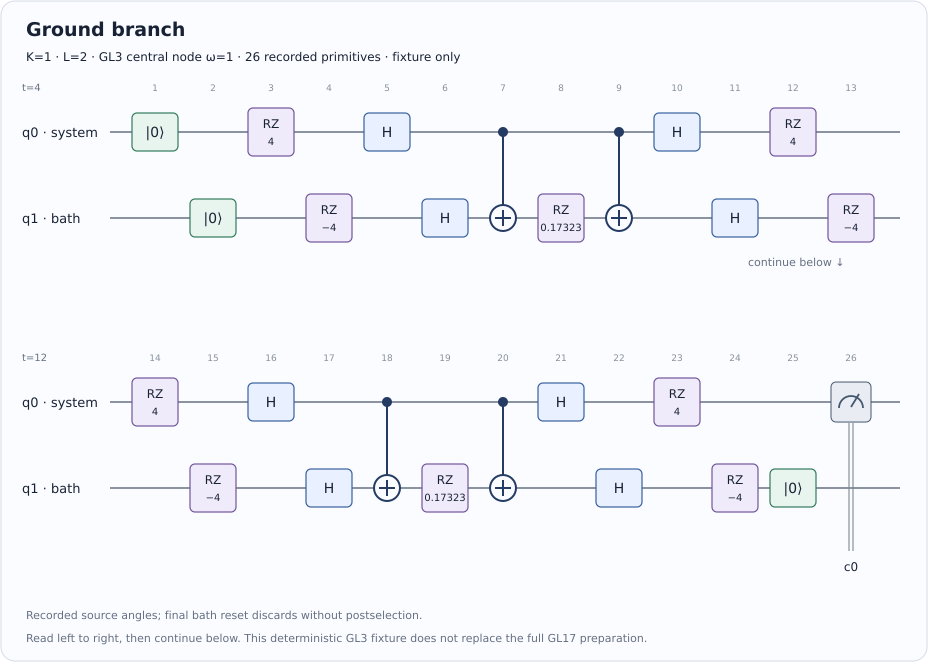

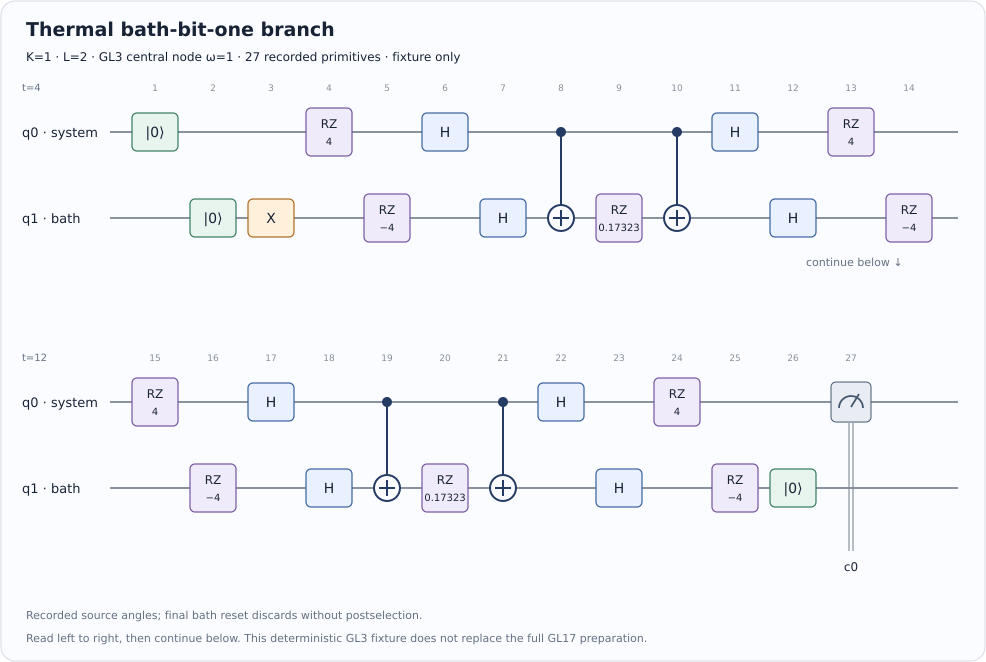

In [3]:
display(JSON(saved_json('fixture-operations.json')))
for name in ('fixture-ground.svg', 'fixture-thermal.svg'):
    display(SVG(data=saved_files[name].decode('utf-8')))


## Finite channel, Gibbs and ground evidence

T17 is the midpoint GL17 channel. Q17_hat and C65_hat are full-Hamiltonian ODE
proxies at 17 and 65 nodes. Same-midpoint source/SDK agreement checks an
implementation component; source/ODE disagreement is a separate Trotter
proxy diagnostic. Four physical inputs span the full reduced map.

The saved endpoint records include full reduced states, Gibbs/ground target
residuals, ground/excited populations, fixed points and 192-round mixing.
Channel and output states are never renormalized. Raw Choi/trace/CP/TP
checks use those unmodified values; only the independent Gibbs target is normalized. None of the finite proxy
comparisons certifies the exact continuous-frequency channel or the complete
.05 ledger. The run status and individual negative/error fields remain visible.


<IPython.core.display.JSON object>

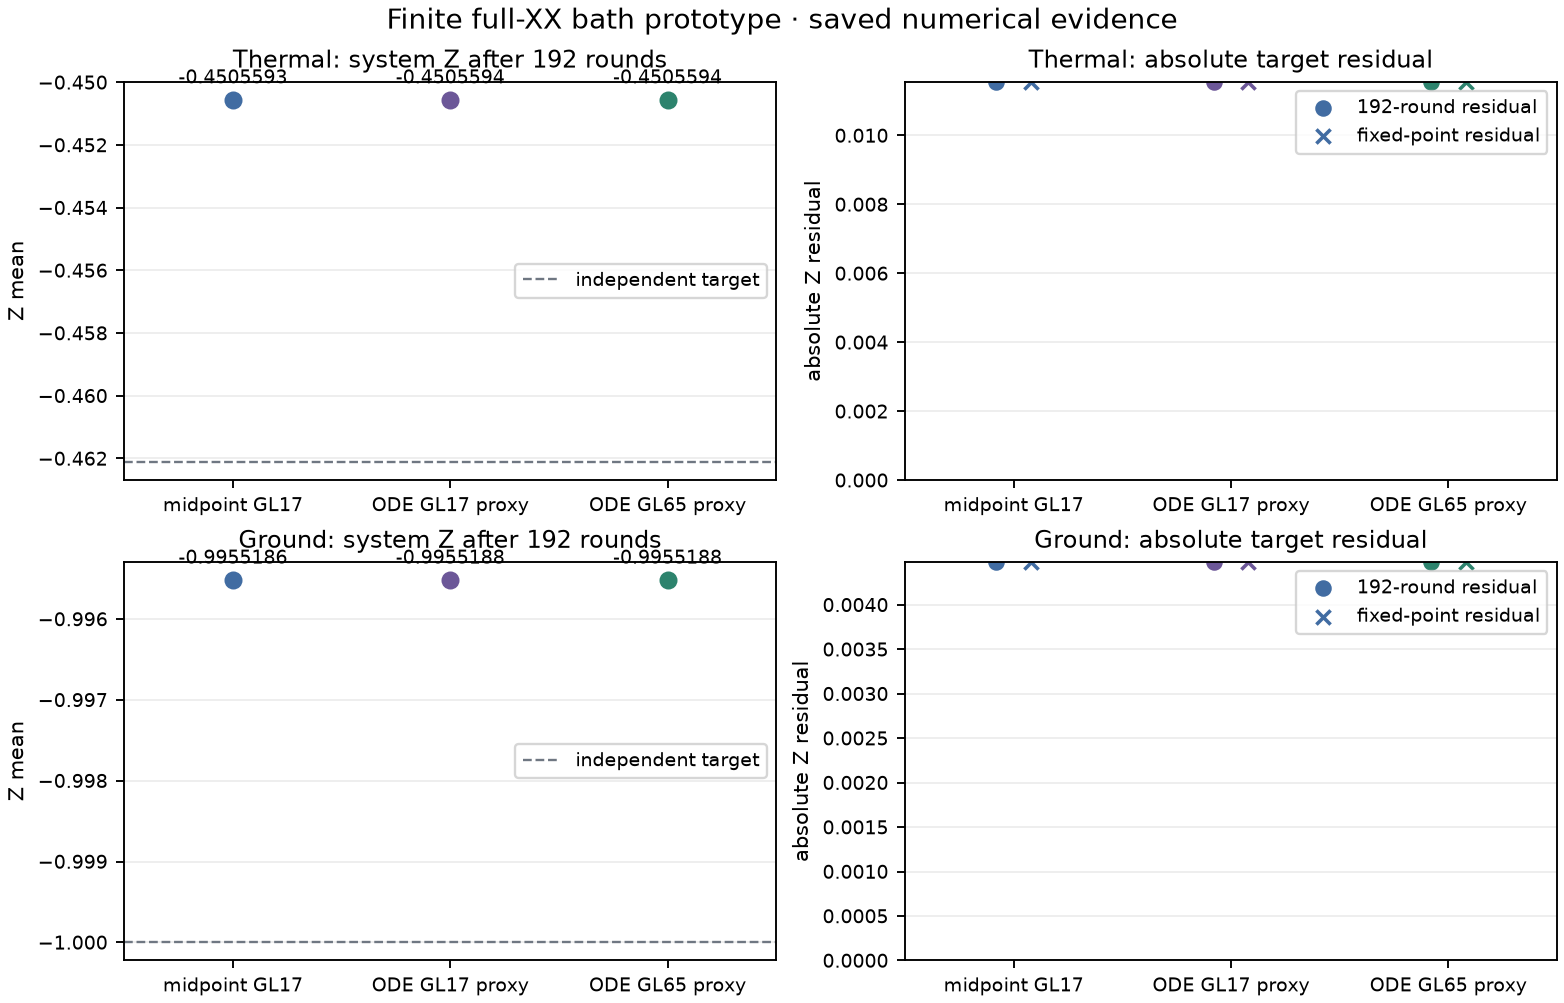

thermal raw saved channel evidence


<IPython.core.display.JSON object>

ground raw saved channel evidence


<IPython.core.display.JSON object>

In [4]:
display(JSON(endpoints))
display(Image(data=saved_files['endpoints.png']))

for mode, entry in results.get('modes', {}).items():
    print(mode, 'raw saved channel evidence')
    channels = {}
    for label, channel in entry.get('channels', {}).items():
        channels[label] = {name: channel[name] for name in (
            'status', 'raw_choi', 'choi_check', 'one_round_state_checks',
            'final_state_checks', 'fixedpoint_check', 'raw_TP_row_residual',
            'affine_A', 'affine_c', 'fixedpoint_state', 'final_state',
            'outputs_after_192', 'mixing_bound_192', 'raw_transfer', 'raw_power_192',
        ) if name in channel}
    display(JSON({'target_state': entry.get('target_state'),
                  'target_Z': entry.get('target_Z'), 'channels': channels}))


## Workload and remaining accounting

The full source ledger charges every forward primitive, optional bath X,
reset and final readout. Compact Operator circuits contain only evolution;
state probes are cached matrix inputs. Scalar K/L/M/P counting is a separate
interface and does not generate coefficients, circuits or reference jobs.
One-spin round/time/frequency scaling is not a completed large-n generator.

The 29,958 complete readout preparations per mode (59,916 total) remain an
unexecuted statistical projection. Coherent error is a complete-preparation
bias; it is not multiplied by this population. Synthesis, T/depth/routing,
physical reset/feedback/noise, idle/controller cost, factories, physical
qubits/runtime and total physical fault success remain uncomputed.


In [5]:
display(JSON(saved_json('primitive-ledger.json')))
print('Saved QASM2 source-export metadata; the full schedules were not quantum simulated')
display(JSON(saved_json('source-exports.json')))
print('Authenticated file inventory; source snapshots are displayed as metadata only')
display(JSON(manifest['files']))


<IPython.core.display.JSON object>

Saved QASM2 source-export metadata; the full schedules were not quantum simulated


<IPython.core.display.JSON object>

Authenticated file inventory; source snapshots are displayed as metadata only


<IPython.core.display.JSON object>

## Source and reproducibility

The implementation and diagrams are original. The scientific-only protocol,
one-spin source, inspection-only numerical source and exact environment lock
are saved in the bundle. This notebook checks their bytes without importing
or executing them. The source recipe hash is only a provenance identifier.

For normal source use, work inside the extracted `source/` directory and pass
`Path("reusable_bath_protocol.json")` explicitly to `load_protocol`; this
uses the bundled scientific protocol and avoids the repository fallback.
`count_source`, `iter_round_operations`, `iter_operations`, `operation_qasm`
and `QASM_HEADER` are standard-library interfaces for counts and bounded
primitive operations. The count CLI is
`python reusable_bath.py --count 192 256 17 --mode ground`.
Counting is not a quantum simulation or a general large-system generator.
The preserved `write_qasm` function needs a managed budget; the numerical
reference needs a bounded caller. They are restricted inspection interfaces,
and no private validation controller or runner is supplied.

Saved execution used Python 3.12.14, NumPy 2.5.4 (BSD-3-Clause), SciPy 1.18.1
(BSD-3-Clause), Qiskit 2.6.2 (Apache-2.0), IPython 9.18.1 and ipykernel 7.4.0.
Replay uses standard-library file, hash and JSON operations plus IPython
JSON, SVG and PNG display in the ordinary locked Jupyter environment.

The motivating method is Ding, Zhan, Preskill and Lin, *Simple and efficient
end-to-end quantum thermal and ground state preparation*, Nature Physics 22,
1679–1683 (2026), DOI 10.1038/s41567-026-03389-y, arXiv:2508.05703v3.
The finite one-spin example does not reproduce the general theorem.
*Efficient quantum thermal simulation*, DOI 10.1038/s41586-025-09583-x, is a
distinct filtered-jump/coherent-correction/access construction.

The successful local display replay does not turn the original full-run
failure into a success, certify the requested total error, or supply a
continuum or physical certificate. `all_components_verified` remains false.
